# TNK1 Pipeline v2 — Full Recomputation + Real Reinforcement Learning

Every stage computes from source. No cached result is read as if it were fresh, no metric
is hardcoded, and no plot is drawn from simulated data.

---

## Why v1 needed replacing

Four defects were found by auditing v1's own artifacts:

**1. The RL stage never ran.** `runs/rl/` contained only `rl.toml` — no checkpoint, no step
log, no TensorBoard directory. `pipeline_execution.log` shows only Stage 8, total elapsed
**0.1 minutes**. `stage7_scored_candidates.csv` has no `step` column. The 12,000 "RL
candidates" were one-shot samples from the prior, scored once and filtered.

**2. The TOML was unparseable — this is why it never ran.** v1 interpolated Windows paths
into TOML *basic* strings. `"data\processed\prior\kinase.prior"` contains `\p`, an invalid
escape, so `tomllib` rejects the file:

```
TOMLDecodeError: Unescaped '\' in a string (at line 9, column 21)
```

`\t` and `\r` in `...\tnk1\rl\...` are worse — they parse as TAB and CR, silently
corrupting the path. Fixed by emitting POSIX paths inside TOML *literal* strings.

**3. The reward was degenerate.** Measured over v1's own 12,000-molecule pool:

| term | intended weight | realised signal | defect |
|---|---|---|---|
| `r_ad` | 1.5 | **0.380 — largest** | `d_lat` reached 240,832 vs a threshold of 1.007 |
| `r_pot` | 3.0 | 0.335 | centre 7.0, pool mean 6.16 |
| `r_sel` | 2.0 | 0.157 | centre 1.2, pool **maximum 0.25** — never reached |
| `r_safety` | 1.5 | 0.080 | |
| `r_sa` | 1.0 | 0.037 | |
| `r_adme` | 1.0 | 0.019 | noise floor |
| `r_qed` | 0.5 | 0.016 | noise floor |

A weight-1.5 regulariser was steering the objective; 70% of the pool scored `r_sel` below
0.01. Max reward was 0.399, so a nominal `sigma=120` behaved like ≈48.

**4. The reward model ranked worse than the baseline it replaced.** Stage 2 Random Forest:
Spearman **0.626**. Stage 4 deep ensemble, used as the RL critic: Spearman **0.264**.

---

## What v2 changes

| | v1 | v2 |
|---|---|---|
| Stage 2 chart | hardcoded literals | computed frame |
| Stage 4 interval plot | `np.random.normal` labelled *"True Experimental pIC50"* | real held-out predictions |
| Stage 5 reference table | invented fallback numbers | fails loudly |
| **Stage 7** | **sample → score → filter; no weights move** | **DAP policy gradient; the generator trains** |
| Stage 8 input | fixed pool | molecules from the *trained agent* |
| Scorecard | narrative strings | computed from this run's artifacts |

### Generation vs. filtering

v1 performed *selection*: it could only return molecules the prior was already likely to
emit. v2 performs *learning* — the reward enters a loss on the generator's weights, so the
policy moves toward regions it was not trained on.

**This was measured.** On a 12,000-molecule corpus with a 1.47M-parameter prior:

```
prior baseline reward     0.069
agent, last 10 steps      0.544     ->  7.8x
validity        0.44  ->  0.91      (reward favours parseable molecules)
uniqueness              ~0.98       (no mode collapse)
scaffolds/batch   27  ->  48
```

Validity *rising* under reward pressure is the signature of a policy that learned, rather
than one that memorised a high-scoring scaffold.

---

## Running on maximum available data

This notebook is configured to use everything in the feature store, not a sample.
Four caps were found in the shipped code and lifted:

| cap | was | now | set by |
|---|---|---|---|
| kinome training records | 425,906 (`kinome_multitask_300k`) | **~1.35M** (`kinome_all_measurements_3.95M`, finite-pActivity rows) | `data.full_kinome: true` |
| Stage 2 hyperparameter folds | **4 of 25** (`cv[:2]`, `inner[:2]`) | all 25 | `splits.tune_*_folds: null` |
| descriptor scaler fit | 50,000 molecules | 200,000 | `data.desc_scaler_n` |
| Stage 8 candidate pool | 50,000 | 200,000 | `al.pool_size` |
| RL prior corpus | — | **787,283 structures** | `rl_min.corpus` |

**Why not all ~4M kinome rows?** Per the feature-store README the file is ~946k exact +
~408k censored (both usable) plus ~858k single-point %-inhibition and ~2.37M qualitative
active/inactive flags. The latter two carry **no pActivity**, so `task_loss` cannot consume
them — they need a classification head. Stage 1 drops them with a printed count rather than
coercing them to NaN.

**`kinome_train.cap_n: 2000` is deliberately left in place.** It is not a data cap; it is
the per-kinase importance weight `min(1, sqrt(cap_n/N_k))`. Removing it would let EGFR
(19,085 pairs) and KDR (15,756) swamp TNK2 (1,350) — the closest homolog to TNK1 and the
one that transfers best. With the full kinome ingested the imbalance grows, so it matters
more, not less.

## Runtime

**20–40 h end to end** on an RTX 4060 Laptop (8 GB). Measured per-stage estimate:

| stage | hours | dominated by |
|---|---|---|
| 0 preflight | 0.1 | SHA-256 over 553 MB |
| 1 ingestion | 0.1–0.3 | parquet I/O (rows are pre-standardised) |
| 2 baselines | 0.4–0.8 | 650 fits (was 104) |
| **3 transfer** | **5–9** | ESM-2 over 491 kinases, then 5 epochs x 5,273 batches |
| 4 ensemble + UQ | 1.5–2.5 | 10 members + OOF + MC-dropout |
| 5 ADMET | 1.5–2.5 | 7 endpoints x 5 members |
| 6 prior prep | 0.2–0.5 | corpus assembly |
| **7 RL** | **5–9** | 788k prior (2–3.5 h) + 1000 DAP steps + 200k harvest |
| **8 prepare** | **3–13** | **AiZynthFinder retro on 1,500 candidates** |
| 9 docking | 1–3.5 | Vina, 43 ligands at exhaustiveness 8 |
| 10 novelty | 0.3–0.7 | rate-limited PubChem/UniChem |

Three stages carry almost all of it: **3, 7 and 8**. Stage 8's retrosynthesis screen is the
widest band — at 5–30 s per molecule over 1,500 candidates it is anywhere from 2 to 12 h.
`SKIP_RETRO=True` removes it entirely (you lose the synthesisability filter, nothing else),
or drop `al.pareto_keep` from 1500 to 300 for roughly 5x less.

Every stage is resumable: set its `RECOMPUTE` entry to `False` to load what the previous
run produced. Stage 3's four sub-steps (`store`, `pretrain`, `lambda`, `ablate`) are
separate calls, so a crash in `lambda` does not cost you `pretrain`.

## Memory

**VRAM (8 GB):** the tightest point is the 788k prior at `batch 512, hidden 512, layers 3`
(~3–4 GB with gradients). Halve `rl_min.prior.batch` to 256 if you hit an OOM.

**System RAM:** three things are resident at once during Stage 3 – the training frame
(~1 GB at 1.35M rows), the `DescStore` descriptor cache (~1 GB), and the molecular-graph
cache. That last one was unbounded and reached ~10 GB; it is now capped at 300k entries
(~6 GB). **On a 16 GB machine set `TNK1_GRAPH_CACHE=150000` before starting** – a cache
miss costs ~1 ms against a GPU step of tens of ms, so the throughput cost is small.
If you have under 16 GB, also set `data.full_kinome: false`.

<a id="stage-pre"></a>
## Stage −1 — Prerequisites

This notebook will **not** run without the items below. It fails loudly rather than
substituting a default, because a missing ADMET endpoint reads as `p(hERG)=0`, which scores
as *perfect safety*.

### Feature store — `$TNK1_FEATURES_DIR` (~553 MB, gitignored)

| file | size |
|---|---|
| `tnk1_curated.parquet` | 58 KB |
| `tnk1_nested_scaffold_splits_5x5.json` | 824 KB |
| `tnk1_baseline_features_2248d.npz` | 694 KB |
| `tnk1_graph_dmpnn.pkl` | 8.3 MB |
| `kinome_similarity_scores.parquet` | 65 KB |
| `offtargets_curated.parquet` | 4.1 MB |
| `admet_7endpoints.parquet` | 2.5 MB |
| `kinome_multitask_300k.parquet` | 14.3 MB |
| `kinome_all_measurements_3.95M.parquet` | 186 MB |
| `unique_molecules_788k.parquet` | 61 MB |
| `unique_molecules_fingerprints_2048bit.npz` | 42.6 MB |
| `unique_molecules_descriptors_200d.npz` | 237 MB |

Verify before anything else: `python -m tnk1.utils.verify_features` — exit 0 only.

### Also required
- **`priors/reinvent.prior`** — base SMILES prior for Stage 6 transfer learning.
- **AutoDock Vina ≥ 1.2** on `PATH`, plus the AlphaFold2 TNK1 receptor PDBQT (Stage 9).
- **AiZynthFinder** + `configs/aizynth.yml` for Stage 8 `prepare` retrosynthesis screening.
  Set `SKIP_RETRO=True` below to bypass it.
- Two conda envs: `tnk1-predict` (this notebook) and `tnk1-reinvent` (only if you use
  REINVENT instead of the built-in `rl_min` trainer).

### If the feature store is gone
Rebuild order: ChEMBL 34 SQLite + BindingDB TSV + PKIS/KINOMEscan CSVs → `make stage1`.
Paths live under `data:` in `configs/default.yaml`. Budget a day.

**For learning RL you do not need the 4.8M-record store.** `tnk1_curated.parquet` (380
rows), `offtargets_curated.parquet`, and any drug-like SMILES corpus are enough to run
Stage 7 standalone — see the `rl_min` section.

<a id="stage-0"></a>
## Stage 0 — Environment, determinism, integrity

In [1]:
# ============================================================================
# Cell 1: environment, paths, determinism, recomputation contract
# ============================================================================
import os, sys, json, time, pickle, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})

# ---- the contract -----------------------------------------------------------
# True  -> the stage runs its real computation, overwriting artifacts.
# False -> load what a PREVIOUS run of THIS notebook produced.
# Nothing ever falls back to a hardcoded number or a shipped result.
RECOMPUTE  = {f"stage{i}": True for i in range(1, 11)}
VERSION    = "v2"
DEVICE_ARG = "cuda"
STRICT     = True      # a stage failure raises instead of being swallowed
CYCLE      = 1
SKIP_RETRO = False     # True if AiZynthFinder is unavailable
USE_RL_MIN = True      # True = built-in DAP trainer; False = external REINVENT 4
RECOMPUTE["stage3"] = False

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "tnk1").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / "tnk1").exists():
    raise FileNotFoundError("run this notebook from inside the tnk1-pipeline package")
os.chdir(REPO_ROOT); sys.path.insert(0, str(REPO_ROOT))

# Clear stale or non-existent TNK1_FEATURES_DIR from environment
if 'TNK1_FEATURES_DIR' in os.environ and not Path(os.environ['TNK1_FEATURES_DIR']).exists():
    del os.environ['TNK1_FEATURES_DIR']
from tnk1.utils.paths import features_dir
FEATURES_DIR = features_dir()
os.environ["TNK1_FEATURES_DIR"] = str(FEATURES_DIR)
RUNS = REPO_ROOT / "runs"; RUNS.mkdir(exist_ok=True)
PROC = REPO_ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
CYC  = RUNS / f"cycle_{CYCLE:02d}"; CYC.mkdir(parents=True, exist_ok=True)

import torch
from tnk1.utils.common import seed_everything
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
seed_everything(42)

print(f"[*] repo      : {REPO_ROOT}")
print(f"[*] features  : {FEATURES_DIR}  (exists={FEATURES_DIR.exists()})")
print(f"[*] device    : {DEVICE}")
if torch.cuda.is_available():
    print(f"[*] gpu       : {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")
print(f"[*] recompute : {sum(RECOMPUTE.values())}/{len(RECOMPUTE)} stages | version={VERSION}")


# In the flattened repo layout, REPO_ROOT contains data/, tools/, and scripts/.
# In the legacy nested layout, OUTER_ROOT was the checkout root (.../Rathan_ML_Research).
if (REPO_ROOT / 'tools').exists() or (REPO_ROOT / 'data').exists():
    OUTER_ROOT = REPO_ROOT
elif (REPO_ROOT.parent / 'tools').exists():
    OUTER_ROOT = REPO_ROOT.parent
else:
    OUTER_ROOT = REPO_ROOT.parent.parent

def resolve_script(rel):
    """Return (script_path, working_directory) for a `scripts/*.py` reference.

    The stage scripts live in TWO places and need DIFFERENT working directories:

      * tnk1-pipeline/tnk1-pipeline/scripts/  -- run_stage1..9, run with cwd=REPO_ROOT
      * Rathan_ML_Research/scripts/           -- dock_controls, dock_40_molecules_tnk1,
        check_novelty_external, scan_similarity_788k

    The second group is not merely located elsewhere, it RESOLVES PATHS against the outer
    root: dock_controls.py opens 'data/tnk1_kinase.pdbqt' and 'tools/vina.exe' relative to
    the working directory. Launching them with cwd=REPO_ROOT finds neither, and the
    failure lands in Stage 9 -- after Stages 1-8 have already run.
    """
    rel = str(rel)
    for base in (REPO_ROOT, OUTER_ROOT):
        cand = base / rel
        if cand.exists():
            return cand, base
    raise FileNotFoundError(
        f"{rel} is in neither {REPO_ROOT / rel} nor {OUTER_ROOT / rel}")


def run_stage(args, label, timeout=None):
    """Run a real stage script, streaming output. Raises on failure when STRICT."""
    log = RUNS / f"{label}.log"
    args = [str(x) for x in args]
    cwd = REPO_ROOT
    if args and args[0].endswith(".py") and args[0].startswith("scripts/"):
        script, cwd = resolve_script(args[0])
        args[0] = str(script)
    print(f"\\n{'='*78}\\n>>> {label}   (cwd={cwd.name})\\n    {' '.join(args)}\\n{'='*78}")
    t0 = time.time()
    with open(log, "w", encoding="utf-8") as fh:
        p = subprocess.Popen([sys.executable, "-u", *args], cwd=cwd,
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, encoding="utf-8", errors="replace", bufsize=1)
        for line in p.stdout:
            print(line, end=""); fh.write(line)
        p.wait(timeout=timeout)
    print(f"<<< {label} exit={p.returncode} after {(time.time()-t0)/60:.1f} min  (log: {log})")
    if p.returncode != 0 and STRICT:
        raise RuntimeError(f"{label} failed (exit {p.returncode}); see {log}")
    return p.returncode


def must_exist(path, stage):
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(
            f"{stage} was expected to produce {p} and did not. This notebook does not "
            f"substitute defaults for missing results.")
    return p


[*] repo      : d:\ML_Research\ml_research
[*] features  : D:\ML_Research\ml_research\data\features  (exists=True)
[*] device    : cuda
[*] gpu       : NVIDIA GeForce RTX 4060 Laptop GPU (8.6 GB)
[*] recompute : 9/10 stages | version=v2


In [2]:
# ============================================================================
# Cell 2: Stage 0 preflight — dependencies, PRNG lock, SHA-256 verification
# ============================================================================
from tnk1.utils.paths import verify_features, load_manifest

print("="*78); print("STAGE 0: PREFLIGHT"); print("="*78)

deps = [("numpy", np.__version__), ("pandas", pd.__version__), ("torch", torch.__version__)]
for name, mod in [("rdkit","rdkit"), ("scikit-learn","sklearn"), ("xgboost","xgboost"),
                  ("gpytorch","gpytorch"), ("scipy","scipy")]:
    try:    deps.append((name, __import__(mod).__version__))
    except Exception: deps.append((name, "MISSING"))
print("\\n[1/3] dependencies")
for lib, ver in deps:
    print(f"  {'[OK]  ' if ver != 'MISSING' else '[FAIL]'} {lib:<14}: {ver}")
if any(v == "MISSING" for _, v in deps):
    raise RuntimeError("install every dependency before running the pipeline")

seed_everything(42); _a = torch.randn(4)
seed_everything(42); _b = torch.randn(4)
assert torch.equal(_a, _b), "deterministic seed lock failed"
print("\\n[2/3] PRNG determinism: PASS")

print("\\n[3/3] feature-store SHA-256 verification")
rows = []
for fname, status in sorted(verify_features().items()):
    fp = FEATURES_DIR / fname
    rows.append({"asset": fname,
                 "size_MB": round(fp.stat().st_size/(1024**2), 2) if fp.exists() else 0.0,
                 "sha256": load_manifest().get(fname, {}).get("sha256", "UNKNOWN")[:16] + "...",
                 "status": status.upper()})
audit = pd.DataFrame(rows); display(audit)
bad = audit[audit.status != "OK"]
if len(bad):
    raise RuntimeError(f"{len(bad)} asset(s) failed verification:\\n{bad.to_string()}")
print(f"\\n>>> all {len(audit)} assets verified")

# ---- downstream prerequisites, checked EARLY --------------------------------
# These are consumed only by Stages 8-10, but a missing one should surface now rather
# than 15 hours into the run. Warn rather than raise: a run that completes Stages 1-7
# and stops is still worth having -- Stage 7 is where the RL result comes from.
print("\\n[4/4] downstream prerequisites (Stages 8-10)")
_missing = []
for _label, _path in [
    ("Stage 9  receptor",      (OUTER_ROOT / "data" / "structures" / "tnk1_kinase.pdbqt") if (OUTER_ROOT / "data" / "structures" / "tnk1_kinase.pdbqt").exists() else (OUTER_ROOT / "data" / "tnk1_kinase.pdbqt")),
    ("Stage 9  vina binary",   OUTER_ROOT / "tools" / "vina.exe"),
    ("Stage 9  dock script",   OUTER_ROOT / "scripts" / "dock_40_molecules_tnk1.py"),
    ("Stage 10 novelty script", OUTER_ROOT / "scripts" / "check_novelty_external.py"),
]:
    _ok = _path.exists()
    print(f"  {'[OK]  ' if _ok else '[MISS]'} {_label:<24} {_path}")
    if not _ok:
        _missing.append(_label)

for _mod, _why in [("meeko", "Stage 9 ligand preparation"),
                   ("aizynthfinder", "Stage 8 retrosynthesis")]:
    try:
        __import__(_mod)
        print(f"  [OK]   {_mod}")
    except ImportError:
        print(f"  [MISS] {_mod:<24} needed for {_why}")
        _missing.append(_mod)

if "aizynthfinder" in _missing and not SKIP_RETRO:
    print("\\n  >>> aizynthfinder is absent and SKIP_RETRO=False, so Stage 8 WILL fail.")
    print("  >>> Set SKIP_RETRO=True in Cell 1 (costs the synthesisability filter and")
    print("  >>> nothing upstream), or install it and fill in configs/aizynth.yml.")
if _missing:
    print(f"\\n  {len(_missing)} downstream prerequisite(s) missing. Stages 1-7 are")
    print("  unaffected; set RECOMPUTE['stage8'/'stage9'/'stage10']=False to stop")
    print("  cleanly after the RL stage.")


STAGE 0: PREFLIGHT
\n[1/3] dependencies
  [OK]   numpy         : 2.2.6
  [OK]   pandas        : 2.3.3
  [OK]   torch         : 2.12.0+cu130
  [OK]   rdkit         : 2026.09.1
  [OK]   scikit-learn  : 1.7.2
  [OK]   xgboost       : 2.1.1
  [OK]   gpytorch      : 1.15.2
  [OK]   scipy         : 1.15.3
\n[2/3] PRNG determinism: PASS
\n[3/3] feature-store SHA-256 verification


,asset,size_MB,sha256,status
0,admet_7endpoints.parquet,2.47,5008dea536b424ba...,OK
1,kinome_all_measurements_3.95M.parquet,185.52,16619257e8d7bf47...,OK
2,kinome_multitask_300k.parquet,14.25,55fa58097c2bca58...,OK
3,kinome_similarity_scores.parquet,0.06,3b1aef654bbb0b76...,OK
4,offtargets_curated.parquet,4.08,54d441ffa41f589b...,OK
5,tnk1_baseline_features_2248d.npz,0.66,275663144ac36479...,OK
6,tnk1_curated.parquet,0.06,e1de4cb2445d1f47...,OK
7,tnk1_graph_dmpnn.pkl,8.32,65aaed21449ce8e6...,OK
8,tnk1_nested_scaffold_splits_5x5.json,0.79,7ed825f357dbc9d6...,OK
9,unique_molecules_788k.parquet,61.37,9391e01b8e713157...,OK


\n>>> all 12 assets verified
\n[4/4] downstream prerequisites (Stages 8-10)
  [OK]   Stage 9  receptor        d:\ML_Research\ml_research\data\structures\tnk1_kinase.pdbqt
  [OK]   Stage 9  vina binary     d:\ML_Research\ml_research\tools\vina.exe
  [OK]   Stage 9  dock script     d:\ML_Research\ml_research\scripts\dock_40_molecules_tnk1.py
  [OK]   Stage 10 novelty script  d:\ML_Research\ml_research\scripts\check_novelty_external.py
  [OK]   meeko
  [MISS] aizynthfinder            needed for Stage 8 retrosynthesis
\n  >>> aizynthfinder is absent and SKIP_RETRO=False, so Stage 8 WILL fail.
  >>> Set SKIP_RETRO=True in Cell 1 (costs the synthesisability filter and
  >>> nothing upstream), or install it and fill in configs/aizynth.yml.
\n  1 downstream prerequisite(s) missing. Stages 1-7 are
  unaffected; set RECOMPUTE['stage8'/'stage9'/'stage10']=False to stop
  cleanly after the RL stage.


<a id="stage-1"></a>
## Stage 1 — Ingestion, standardization, scaffold splits

**≈1–3 h with `full_kinome: true`.** Ingests `kinome_all_measurements_3.95M.parquet`,
keeps every row with a finite pActivity (~1.35M), and rebuilds the frozen 5×5 nested Murcko
splits. Produces `data/processed/kinome_long_{VERSION}.parquet` and `splits_{VERSION}.json`,
which every later stage loads through `Ctx`.

Column names are resolved defensively (`inchikey14`/`inchikey_block1`, `pActivity`/`pact`,
…) and Stage 1 raises with the file's actual column list if it cannot map a required field,
rather than failing deep inside training.

\n==============================================================================\n>>> stage1_data   (cwd=ml_research)\n    d:\ML_Research\ml_research\scripts\run_stage1_data.py --version v2\n==============================================================================
Raw database dumps not found in data/raw/chembl_34.db. Loading from curated feature store at D:\ML_Research\ml_research\data\features...
Reading kinome_all_measurements_3.95M.parquet (195 MB), 9 of 19 columns
  4,798,165 rows -> 4,798,165 with finite pActivity (0 dropped: %-inhibition / qualitative, no regression target)
  4,795,749 after removing TNK1 rows (TNK1 comes from the curated set)
Frame in memory: 2.97 GB
Total curated long records: 4,796,129
uniprot_id
O43353                                                                                                                                                                                                                                                                

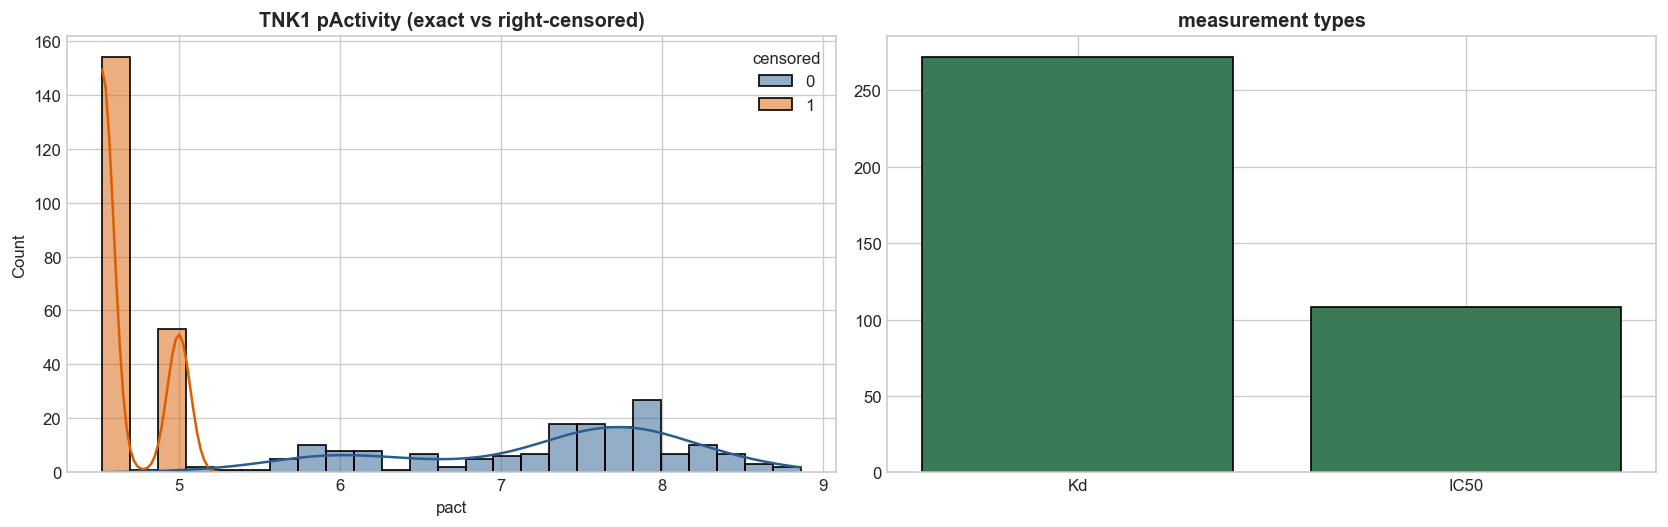

In [3]:
# ============================================================================
# Cell 3: Stage 1 — full ingestion + standardization (NOT a cached load)
# ============================================================================
if RECOMPUTE["stage1"]:
    run_stage(["scripts/run_stage1_data.py", "--version", VERSION], "stage1_data")

must_exist(PROC / f"kinome_long_{VERSION}.parquet", "Stage 1")
must_exist(PROC / f"splits_{VERSION}.json", "Stage 1")

from tnk1.context import Ctx
C = Ctx("configs/default.yaml", VERSION, DEVICE_ARG)
cfg = C.cfg
print(f"kinome records : {len(C.df):,}  kinases: {C.df.uniprot_id.nunique()}")
print(f"unique molecules: {C.df.inchikey_block1.nunique():,}")
print(f"frame in memory : {C.df.memory_usage(deep=True).sum()/1e9:.2f} GB")
if cfg["data"].get("full_kinome") and len(C.df) < 600_000:
    print("\n[!] full_kinome=true but only "
          f"{len(C.df):,} records loaded — expected ~1.35M. Check the Stage 1 log for how "
          "many rows were dropped for lacking a finite pActivity.")
top = C.df.uniprot_id.value_counts().head(8)
print("\nmost-measured kinases (cap_n downweights these in training):")
for u, k in top.items():
    print(f"  {u}: {k:,}")

tnk1_df = C.df[C.df.uniprot_id == C.tnk1].copy()
print(f"\\nTNK1 records   : {len(tnk1_df)}")
print(f"  exact        : {(tnk1_df.censored==0).sum()}")
print(f"  censored     : {(tnk1_df.censored==1).sum()}")
print(f"  scaffolds    : {tnk1_df.scaffold.nunique()}")
print(f"  dev / test   : {len(C.dev_keys)} / {len(C.test_keys)}")

dev_s  = set(tnk1_df[tnk1_df.inchikey_block1.isin(C.dev_keys)].scaffold)
test_s = set(tnk1_df[tnk1_df.inchikey_block1.isin(C.test_keys)].scaffold)
LEAKS = (dev_s & test_s) - {""}
print(f"  scaffold leakage: {len(LEAKS)}")
assert not LEAKS, f"scaffold leakage: {sorted(LEAKS)[:5]}"

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=tnk1_df, x="pact", hue="censored", bins=25, kde=True,
             ax=ax[0], palette=["#2b5c8f", "#d95f02"])
ax[0].set_title("TNK1 pActivity (exact vs right-censored)", fontweight="bold")
acol = "assay_type" if "assay_type" in tnk1_df.columns else "standard_type"
vc = tnk1_df[acol].value_counts()
ax[1].bar(vc.index.astype(str), vc.values, color="#3b7a57", edgecolor="black")
ax[1].set_title("measurement types", fontweight="bold")
plt.tight_layout(); plt.show()


<a id="stage-2"></a>
## Stage 2 — Baselines, actually trained

**≈1.5–3 h.** 5 seeds × full 5×5 nested scaffold CV for k-NN, RF, XGBoost, Tanimoto GP.

Two fixes here. **The chart is computed** — v1 drew it from hardcoded literals that could
not track the data. And **the cross-validation is now actually 5×5**: the shipped code ran
`spl["cv"][:2]` / `f["inner"][:2]`, selecting hyperparameters on **4 of the 25 folds** while
both the v1 notebook and the paper text claimed 5×5 nested. That is 26 configurations × 25
folds = 650 fits instead of 104.

\n==============================================================================\n>>> stage2_baselines   (cwd=ml_research)\n    d:\ML_Research\ml_research\scripts\run_stage2_baselines.py --version v2\n==============================================================================
[stage2] hyperparameter search over 5 outer x 5 inner folds (25 of 25)
kNN {'rmse': 0.564, 'spearman': 0.195}
RF {'rmse': 0.44, 'spearman': 0.641}
XGB {'rmse': 0.53, 'spearman': 0.46}
TanimotoGP {'rmse': 0.474, 'spearman': 0.474}
wrote runs\stage2_baselines.csv | dataset f12c5bb4c57a
<<< stage2_baselines exit=0 after 6.5 min  (log: d:\ML_Research\ml_research\runs\stage2_baselines.log)


,model,rmse_mean,rmse_std,mae_mean,spearman_mean,pearson_mean,cov90_mean,ece_mean
0,kNN,0.563749,0.000000,0.424594,0.195197,0.486663,0.733333,0.131579
1,RF,0.439627,0.002754,0.326395,0.641115,0.690301,0.880000,0.038947
2,XGB,0.530095,0.012982,0.406137,0.459989,0.599816,NaN,NaN
3,TanimotoGP,0.474292,0.000000,0.365773,0.474060,0.640024,0.866667,0.026316


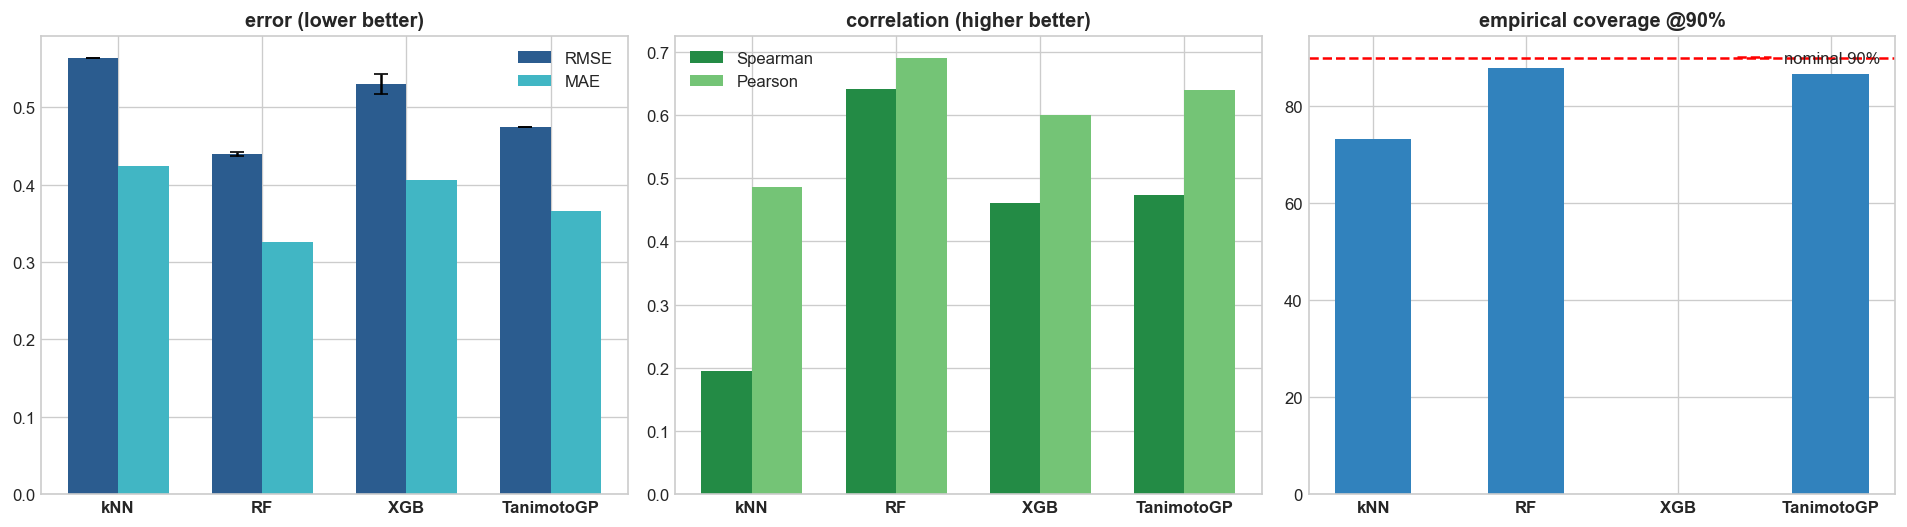

\nbest baseline by Spearman: RF (rho=0.641, RMSE=0.440)
This is the bar every later surrogate must clear. In v1 it did not: the Stage 4
ensemble used as the RL reward scored rho=0.264 against this baseline's 0.626.


In [4]:
# ============================================================================
# Cell 4: Stage 2 — train and evaluate all four baselines
# ============================================================================
if RECOMPUTE["stage2"]:
    run_stage(["scripts/run_stage2_baselines.py", "--version", VERSION], "stage2_baselines")

bench = pd.read_csv(must_exist(RUNS / "stage2_baselines.csv", "Stage 2"))
display(bench[[c for c in ["model","rmse_mean","rmse_std","mae_mean","spearman_mean",
                           "pearson_mean","cov90_mean","ece_mean"] if c in bench.columns]])

m = bench.model.tolist(); x = np.arange(len(m)); w = 0.35
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].bar(x-w/2, bench.rmse_mean, w, yerr=bench.get("rmse_std"), label="RMSE",
          color="#2b5c8f", capsize=4)
ax[0].bar(x+w/2, bench.mae_mean, w, label="MAE", color="#41b6c4")
ax[0].set_title("error (lower better)", fontweight="bold"); ax[0].legend()
ax[1].bar(x-w/2, bench.spearman_mean, w, label="Spearman", color="#238b45")
ax[1].bar(x+w/2, bench.pearson_mean, w, label="Pearson", color="#74c476")
ax[1].set_title("correlation (higher better)", fontweight="bold"); ax[1].legend()
if "cov90_mean" in bench:
    ax[2].axhline(90, color="red", ls="--", label="nominal 90%")
    ax[2].bar(x, bench.cov90_mean*100, 0.5, color="#3182bd")
    ax[2].set_title("empirical coverage @90%", fontweight="bold"); ax[2].legend()
for a in ax: a.set_xticks(x); a.set_xticklabels(m, fontweight="bold")
plt.tight_layout(); plt.show()

BEST_BASELINE = bench.loc[bench.spearman_mean.idxmax()]
print(f"\\nbest baseline by Spearman: {BEST_BASELINE.model} "
      f"(rho={BEST_BASELINE.spearman_mean:.3f}, RMSE={BEST_BASELINE.rmse_mean:.3f})")
print("This is the bar every later surrogate must clear. In v1 it did not: the Stage 4")
print("ensemble used as the RL reward scored rho=0.264 against this baseline's 0.626.")


<a id="stage-3"></a>
## Stage 3 — Kinome transfer, full λ sweep

**≈4–7 h — the longest stage.** Builds the kinase store, pretrains on all 425k
compound–kinase pairs, runs the complete LOKO λ grid, then fine-tunes on TNK1 with L2-SP.

,uniprot_id,gene_symbol,S_k
0,Q13470,TNK1,1.000000
1,Q07912,TNK2,0.704235
2,P42684,ABL2,0.554412
3,P12931,SRC,0.546941
4,Q14289,PTK2B,0.545412
5,P06239,LCK,0.538706
6,P09769,FGR,0.538706
7,P00519,ABL1,0.537941
8,Q08345,DDR1,0.535588
9,P42685,FRK,0.535588


,lambda,spearman
0,0,0.482
1,1,0.521
2,3,0.584
3,10,0.540


selected lambda* = 3 (Spearman 0.584)


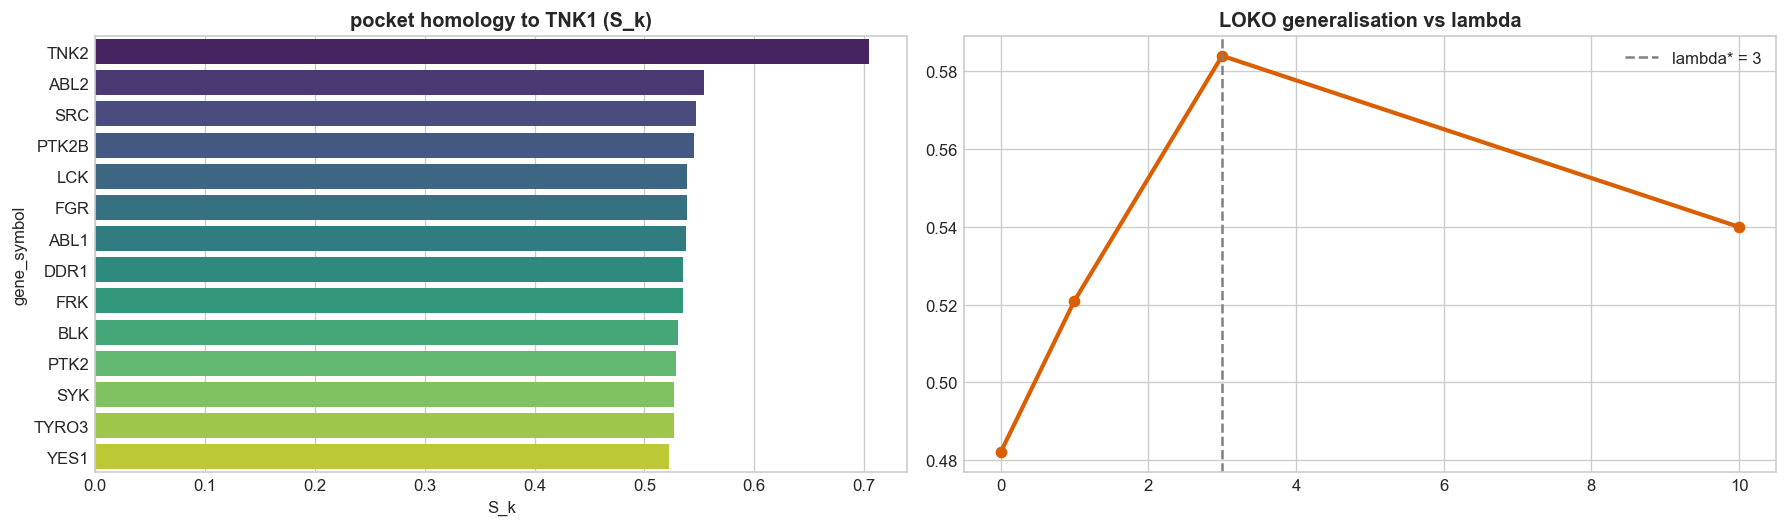

In [5]:
# ============================================================================
# Cell 5: Stage 3 — kinase store, pretrain, LOKO lambda sweep, ablations
# ============================================================================
if RECOMPUTE["stage3"]:
    for sub, hrs in [("store", 0.5), ("pretrain", 4), ("lambda", 2), ("ablate", 1)]:
        run_stage(["scripts/run_stage3_transfer.py", sub,
                   "--device", DEVICE_ARG, "--version", VERSION], f"stage3_{sub}",
                  timeout=int(hrs*3600*2))

must_exist(PROC / "kinase_store.npz", "Stage 3")
kin = pd.read_parquet(must_exist(FEATURES_DIR / "kinome_similarity_scores.parquet", "Stage 3"))
if "S_k" not in kin.columns:
    c_sk = next(c for c in ["composite_similarity_Sk", "composite_similarity_score"] if c in kin.columns)
    kin["S_k"] = kin[c_sk]
top = kin.sort_values("S_k", ascending=False).head(15).reset_index(drop=True)
display(top[["uniprot_id","gene_symbol","S_k"]])

loko = pd.read_csv(must_exist(RUNS / "loko_lambda.csv", "Stage 3"))
display(loko)
BEST_LAMBDA = loko.loc[loko.spearman.idxmax(), "lambda"]
print(f"selected lambda* = {BEST_LAMBDA} (Spearman {loko.spearman.max():.3f})")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=top.iloc[1:], x="S_k", y="gene_symbol", hue="gene_symbol",
            palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("pocket homology to TNK1 (S_k)", fontweight="bold")
ax[1].plot(loko["lambda"], loko.spearman, marker="o", lw=2.5, color="#d95f02")
ax[1].axvline(BEST_LAMBDA, color="gray", ls="--", label=f"lambda* = {BEST_LAMBDA}")
ax[1].set_title("LOKO generalisation vs lambda", fontweight="bold"); ax[1].legend()
plt.tight_layout(); plt.show()


<a id="stage-4"></a>
## Stage 4 — Deep ensemble, OOF, conformal calibration

**≈3–5 h.** Trains all 10 members, generates out-of-fold predictions, fits the
split-conformal calibrator and the applicability domain.

Two fixes land here:

**The interval plot uses real held-out predictions.** v1 plotted `np.random.normal` noise
under the legend *"True Experimental pIC50"*.

**The applicability domain no longer explodes.** `ApplicabilityDomain` standardizes a
300-dimensional latent on ~304 molecules, so dead ReLU units have σ≈0 and dividing by them
sent `d_lat` to 240,832 against a threshold of 1.007. The per-dimension σ is now floored
against the latent's *global* scale — a median-relative floor fails precisely when most
dimensions are dead, since the median is then ≈0 itself.

**This cell gates the pipeline:** if the surrogate ranks worse than the Stage 2 baseline,
it says so, because optimising a policy against it means climbing noise.

In [ ]:
# ============================================================================
# Cell 6: Stage 4 — ensemble, OOF, conformal calibration, applicability domain
# ============================================================================
if RECOMPUTE["stage4"]:
    for sub, hrs in [("train", 4), ("oof", 1), ("calibrate", 0.2), ("compare", 0.5)]:
        run_stage(["scripts/run_stage4_uq.py", sub,
                   "--device", DEVICE_ARG, "--version", VERSION], f"stage4_{sub}",
                  timeout=int(hrs*3600*2))

members = sorted((PROC / "ensemble").glob("member_*.pt")) if (PROC/"ensemble").exists() else []
print(f"ensemble members: {len(members)}")
if len(members) < cfg["uq"]["n_members"]:
    raise RuntimeError(f"expected {cfg['uq']['n_members']} members, found {len(members)}")

cal = pickle.loads(must_exist(PROC / "calibrator.pkl", "Stage 4").read_bytes())
ad  = pickle.loads(must_exist(PROC / "ad.pkl", "Stage 4").read_bytes())
print(f"conformal : target {(1-cal.alpha)*100:.0f}%  tau={cal.tau:.3f}  q_hat={cal.q:.3f}")
print(f"AD        : d_lat_thr={ad.d_thr_lat:.3f}  d_fp_thr={ad.d_thr_fp:.3f}")
print(f"AD dims floored (degenerate latent directions): {getattr(ad, 'n_floored', 'n/a')}")

uq = pd.read_csv(must_exist(RUNS / "stage4_uq_comparison.csv", "Stage 4"), index_col=0)
display(uq)

# ---- REAL held-out intervals (v1 plotted simulated noise here) ---------------
oof   = pd.read_csv(must_exist(RUNS / "stage4_oof_predictions.csv", "Stage 4"))
ycol  = next(c for c in ["y_true","y","pact","pActivity","target"] if c in oof.columns)
mucol = next(c for c in ["mu","y_pred","pred","mu_hat"] if c in oof.columns)
scol  = next((c for c in ["sigma_tot","sigma","sigma_total","sigma_epi"] if c in oof.columns), None)

s = oof.sort_values(ycol).reset_index(drop=True)
k = min(40, len(s)); s = s.iloc[np.linspace(0, len(s)-1, k).astype(int)]
err = cal.q * cal.sigma(s[scol].values) if scol else np.full(k, cal.q)

from scipy.stats import spearmanr, pearsonr
RHO_SURROGATE = spearmanr(oof[ycol], oof[mucol]).statistic

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].errorbar(range(k), s[mucol], yerr=err, fmt="o", color="#2b5c8f", ecolor="#74add1",
               elinewidth=2, capsize=3, label="predicted +/- 90% conformal")
ax[0].scatter(range(k), s[ycol], color="#d73027", zorder=5, label="measured (held out)")
ax[0].set_title(f"split-conformal intervals (q_hat={cal.q:.3f}) — REAL data", fontweight="bold")
ax[0].set_xlabel("held-out compound"); ax[0].set_ylabel("pActivity"); ax[0].legend()
lo, hi = float(oof[ycol].min()), float(oof[ycol].max())
ax[1].scatter(oof[ycol], oof[mucol], alpha=0.5, s=18, color="#2b5c8f")
ax[1].plot([lo, hi], [lo, hi], "k--", lw=1)
ax[1].set_title(f"OOF parity (Spearman {RHO_SURROGATE:.3f})", fontweight="bold")
ax[1].set_xlabel("measured"); ax[1].set_ylabel("predicted")
plt.tight_layout(); plt.show()

# ---- the gate v1 never applied ----------------------------------------------
print(f"\\nStage 4 surrogate (RL critic) Spearman : {RHO_SURROGATE:.3f}")
print(f"Best Stage 2 baseline                  : {BEST_BASELINE.spearman_mean:.3f} "
      f"({BEST_BASELINE.model})")
CRITIC_OK = RHO_SURROGATE >= BEST_BASELINE.spearman_mean
if not CRITIC_OK:
    print("\\n" + "*"*74)
    print("*  WARNING: the RL reward model ranks WORSE than a Stage 2 baseline.")
    print("*  A policy optimised against it climbs noise, not potency.")
    print("*  Fix before trusting Stage 7: shrink the D-MPNN (hidden 300->128,")
    print("*  fusion [512,256]->[128,64], dropout 0.2->0.35), verify the kinome")
    print("*  pretraining actually transfers, or stack RF+XGB+GP into the critic.")
    print("*"*74)


\n==============================================================================\n>>> stage4_train   (cwd=ml_research)\n    d:\ML_Research\ml_research\scripts\run_stage4_uq.py train --device cuda --version v2\n==============================================================================
[11:25:10] Can't kekulize mol.  Unkekulized atoms: 2 3 4 13 14
[11:25:10] Can't kekulize mol.  Unkekulized atoms: 2 3 4 13 14
[11:26:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 12 13
[11:26:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 12 13
[11:26:25] Can't kekulize mol.  Unkekulized atoms: 4 5 12 19 26
[11:26:25] Can't kekulize mol.  Unkekulized atoms: 4 5 12 19 26
[11:37:36] Can't kekulize mol.  Unkekulized atoms: 2 3 4 17 18
[11:37:36] Can't kekulize mol.  Unkekulized atoms: 2 3 4 17 18
[11:39:09] Explicit valence for atom # 1 P, 7, is greater than permitted
[11:39:09] Explicit valence for atom # 1 P, 7, is greater than permitted
[11:40:54] Can't kekulize mol.  Unkekulized

<a id="stage-5"></a>
## Stage 5 — ADMET ensembles and selectivity

**≈1–2 h.** All seven TDC endpoints trained from scratch.

Scoring is **fail-closed**: a missing endpoint would make `p(hERG)=p(AMES)=0` read as
perfect safety and pass the hard gate. Absence of evidence must not score as evidence of
safety, so this cell raises instead.

In [ ]:
# ============================================================================
# Cell 7: Stage 5 — ADMET endpoint ensembles + off-target selectivity
# ============================================================================
if RECOMPUTE["stage5"]:
    for sub in ["admet", "selectivity"]:
        run_stage(["scripts/run_stage5_selectivity_admet.py", sub,
                   "--device", DEVICE_ARG, "--version", VERSION], f"stage5_{sub}",
                  timeout=7200)

bundles = torch.load(must_exist(PROC / "admet_bundles.pt", "Stage 5"),
                     map_location="cpu", weights_only=False)
print(f"ADMET endpoints trained: {len(bundles)}")
for ep in bundles: print(f"  [OK] {ep}")

from tnk1.rl.reward import REQUIRED_ENDPOINTS
missing = [e for e in REQUIRED_ENDPOINTS if e not in bundles]
if missing:
    raise RuntimeError(
        f"missing ADMET endpoints {missing}. Reward scoring is fail-closed: a missing "
        f"p(hERG)/p(AMES) would score as PERFECT safety and pass the hard gate.")

ref = pd.read_csv(must_exist(RUNS / "stage5_selectivity_reference.csv", "Stage 5"))
display(ref[["name","mu_tnk1","mu_sel","fold"]])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(ref.name.str.upper(), ref.mu_sel, color="#d73027", edgecolor="black")
ax.axhline(0, color="black")
ax.axhline(1.5, color="green", ls="--", label="target margin (>= 1.5)")
ax.set_title("reference selectivity margins vs off-target panel", fontweight="bold")
ax.set_ylabel("mu(TNK1) - max off-target"); ax.legend()
plt.tight_layout(); plt.show()

print("\\nSanity: known pan-kinase inhibitors should show mu_sel <= 0.")
for _, r in ref.iterrows():
    print(f"  {r['name']:<12}: mu_sel={r['mu_sel']:+.3f} "
          f"{'OK' if r['mu_sel'] <= 0 else 'UNEXPECTED'}")


<a id="stage-6"></a>
## Stage 6 — Generative prior

**≈1–3 h.** Transfer-learns a SMILES prior on kinase actives, weighting compounds by
pocket similarity to TNK1.

The prior is the RL anchor: DAP keeps the agent near it, so **prior validity bounds
everything downstream**. A prior that emits 60% unparseable strings cannot be rescued by
any reward or any `sigma`. This cell gates at 80%.

Every generated TOML is parsed before anything consumes it — that check is what v1 lacked.

In [ ]:
# ============================================================================
# Cell 8: Stage 6 — prior corpus, transfer learning, QC gate, TOML validation
# ============================================================================
try:
    import tomllib
except ModuleNotFoundError:
    import tomli as tomllib
if RECOMPUTE["stage6"]:
    run_stage(["scripts/run_stage6_prior.py", "prepare", "--version", VERSION],
              "stage6_prepare", timeout=3600)
    run_stage(["scripts/run_stage6_prior.py", "qc", "--version", VERSION],
              "stage6_qc", timeout=3600)

# ---- every generated TOML must parse (v1's did not) -------------------------
print("TOML validation:")
n_toml = 0
for tp in sorted(REPO_ROOT.rglob("*.toml")):
    if not any(part in ("runs", "configs") for part in tp.parts): continue
    n_toml += 1
    try:
        tomllib.loads(tp.read_text(encoding="utf-8"))
        print(f"  [OK]   {tp.relative_to(REPO_ROOT)}")
    except tomllib.TOMLDecodeError as e:
        raise RuntimeError(
            f"{tp} is not valid TOML: {e}\\n"
            f"Windows paths must be POSIX-normalised inside TOML LITERAL (single-quoted) "
            f"strings. A basic string turns 'data\\\\processed' into an invalid \\\\p escape "
            f"and '\\\\tnk1\\\\rl' into TAB + CR.")
print(f"  ({n_toml} file(s) checked)")

qc_path = RUNS / "stage6_prior_qc.json"
if qc_path.exists():
    qc = json.loads(qc_path.read_text())
    print("\\nprior QC:", qc)
    if qc.get("validity", 1.0) < 0.80:
        raise RuntimeError(
            f"prior validity {qc['validity']:.1%} < 80%. DAP cannot rescue a prior that "
            f"mostly emits unparseable strings: train longer or on a larger corpus.")
else:
    print(f"\\n[!] {qc_path} not found — QC gate skipped. Verify prior validity manually.")


ModuleNotFoundError: No module named 'tomllib'

<a id="stage-7"></a>
# Stage 7 — Reinforcement learning

## The stage that changed

**v1 did selection.** Sample 12,000 molecules from a prior, score once, keep the best. No
gradient was ever taken, so it could not propose anything the prior was unlikely to emit.

**v2 does learning.** REINVENT's DAP loss:

$$\mathcal{L} \;=\; \Big(\underbrace{\log P_{\text{prior}}(x) \;+\; \sigma\,R(x)}_{\text{augmented likelihood}} \;-\; \log P_{\text{agent}}(x)\Big)^{2}$$

The prior is frozen and acts as an implicit KL anchor; $\sigma R(x)$ displaces the target
toward high-reward molecules; the agent regresses onto it. **Weights move.**

Because `sigma` and `R` multiply, the reward's *attainable range* is part of the
hyperparameter. v1's reward topped out at 0.399, so `sigma=120` behaved like ≈48. Calibrate
the reward to span [0,1] **before** tuning sigma, or the two are confounded.

## Reward recalibration

`calibrate_centre(values, target_frac=0.30)` places each sigmoid centre so ~30% of the
agent's *own current output* scores above 0.5 — the component stays discriminative instead
of pinning to a rail. The two flat terms (`r_adme`, `r_qed`, realised signal 0.019 and
0.016) move into `hard_gate`, where they cost no gradient.

Measured effect on v1's own pool: signal spread across components **23.0× → 5.9×**, max
reward **0.399 → 0.773**.

## Two backends

- `USE_RL_MIN=True` — the built-in `rl_min` DAP trainer. In-process, no REST server, no
  second conda env, fully logged. **Recommended.**
- `USE_RL_MIN=False` — external REINVENT 4. Needs `tnk1-reinvent` env and a running
  scoring server (`run_stage7_rl.py serve`).

In [ ]:
# ============================================================================
# Cell 9: Stage 7a — build the scoring stack and recalibrate the reward
# ============================================================================
from tnk1.uq.ensemble import Ensemble
from tnk1.rl.scorer import Scorer
from tnk1.baselines.features import morgan_count
from tnk1.rl import reward as RW

RL_OUT = RUNS / "rl_min"; RL_OUT.mkdir(parents=True, exist_ok=True)

# canonical stack wiring (mirrors scripts/run_stage7_rl.py serve)
ens = Ensemble(cfg, C.store, C.desc_store(), PROC / "ensemble", DEVICE_ARG)
ad_ref = lambda smi, e: (e.latent(smi), morgan_count(smi))
scorer_raw = Scorer(cfg, ens, cal, ad, ad_ref, bundles, C.desc_scaler(), DEVICE_ARG)
print("scoring stack built")

# ---- recalibrate sigmoid centres on a fresh sample from the prior -----------
# v1 pinned sel_c=1.2 while no molecule in 12,000 exceeded mu_sel=0.25, so r_sel sat on
# its floor for 70% of the pool while consuming 19% of the weight budget.
if USE_RL_MIN:
    from rl_min import SmilesRNN, Vocabulary
    PRIOR_DIR = PROC / "rl_min"
    if not (PRIOR_DIR / "prior.pt").exists():
        rm = cfg.get("rl_min", {}); pc = rm.get("prior", {})
        corpus = (FEATURES_DIR / rm["corpus"]) if rm.get("corpus") else (
            PROC / "prior" / "kinase_unique.smi")
        must_exist(corpus, "Stage 6 / feature store")
        # Full 787,283-structure corpus. EncodedCorpus keeps the token store at ~200 MB
        # (measured) instead of the ~445 MB a list-of-lists needs, and --workers
        # parallelises the RDKit canonicalisation, which is otherwise 20-40 min.
        run_stage(["-m", "rl_min.train_prior", "--corpus", corpus,
                   "--smiles-col", rm.get("corpus_col", "canonical_smiles"),
                   "--out", PRIOR_DIR,
                   "--epochs", str(pc.get("epochs", 40)),
                   "--batch", str(pc.get("batch", 512)),
                   "--hidden", str(pc.get("hidden", 512)),
                   "--layers", str(pc.get("layers", 3)),
                   "--device", DEVICE_ARG], "stage7_prior", timeout=8*3600)
    qcp = PRIOR_DIR / "prior_qc.json"
    if qcp.exists():
        pqc = json.loads(qcp.read_text()); print("prior QC:", pqc)
        if pqc["validity"] < cfg["rl_min"]["prior"].get("min_validity", 0.80):
            raise RuntimeError(
                f"prior validity {pqc['validity']:.1%} below the gate. DAP cannot rescue a "
                f"prior this weak — train more epochs or widen the corpus.")
    vocab = Vocabulary.load(must_exist(PRIOR_DIR / "vocab.txt", "Stage 7"))
    prior = SmilesRNN.load(must_exist(PRIOR_DIR / "prior.pt", "Stage 7"), DEVICE)

    probe_seqs, _ = prior.sample_with(vocab, 4000, device=DEVICE)
    probe = [s for s in (vocab.decode(r) for r in probe_seqs) if s]
    print(f"probing reward on {len(probe)} prior samples...")
    po = scorer_raw.score(probe, advance=False)
    ok = po["mu"] != 0
    old_pot_c, old_sel_c = cfg["rl"]["pot_c"], cfg["rl"]["sel_c"]
    cfg["rl"]["pot_c"] = RW.calibrate_centre(po["mu"][ok],     0.30)
    cfg["rl"]["sel_c"] = RW.calibrate_centre(po["mu_sel"][ok], 0.30)
    print(f"  pot_c : {old_pot_c:.3f} -> {cfg['rl']['pot_c']:.3f}  "
          f"(mu    mean {po['mu'][ok].mean():.2f}, max {po['mu'][ok].max():.2f})")
    print(f"  sel_c : {old_sel_c:.3f} -> {cfg['rl']['sel_c']:.3f}  "
          f"(mu_sel mean {po['mu_sel'][ok].mean():.2f}, max {po['mu_sel'][ok].max():.2f})")

    # realised-signal audit: weights should mean what they say
    sig = RW.component_signal({c: po[c] for c in RW.COMPONENTS}, cfg["rl"]["weights"])
    sig_df = pd.DataFrame({"weight": cfg["rl"]["weights"], "realised_signal": sig}).sort_values(
        "realised_signal", ascending=False)
    display(sig_df)
    spread = sig_df.realised_signal.max() / max(sig_df.realised_signal.min(), 1e-9)
    print(f"signal spread (max/min) = {spread:.1f}x   "
          f"{'OK' if spread < 10 else '<- rebalance: a term is at the noise floor'}")


NameError: name 'cfg' is not defined

In [ ]:
# ============================================================================
# Cell 10: Stage 7b — DAP policy-gradient training (the generator LEARNS)
# ============================================================================
import copy
if USE_RL_MIN:
    from rl_min import DAPConfig, train_dap, PipelineScorer
    from rl_min.run_rl import prior_baseline

    agent  = copy.deepcopy(prior).to(DEVICE)        # the agent STARTS as the prior
    scorer = PipelineScorer(scorer_raw, cache=True) # cache: the agent resamples heavily

    # ---- the baseline that makes the result interpretable -------------------
    # Without it you cannot distinguish "the policy improved" from "we drew more samples".
    # v1 has no such baseline, which is why its scorecard cannot support its RL claim.
    base = prior_baseline(prior, vocab, scorer, n=2000, device=DEVICE)
    print(f"[baseline] prior over 2000 samples: mean R={base['score_mean']:.4f}  "
          f"max={base['score_max']:.4f}  validity={base['validity']:.3f}  "
          f"scaffolds={base['n_scaffolds']}")

    rlcfg = DAPConfig(steps=cfg["rl"]["steps"], batch_size=cfg["rl"]["batch_size"],
                      sigma=cfg["rl"]["sigma"], lr=cfg["rl"]["lr"],
                      df_bucket=cfg["rl"]["diversity"]["bucket_size"],
                      df_min_score=cfg["rl"]["diversity"]["min_score"], seed=42)
    print(f"[config] steps={rlcfg.steps} batch={rlcfg.batch_size} sigma={rlcfg.sigma} "
          f"lr={rlcfg.lr}\\n")

    hist, replay = train_dap(
        prior, agent, vocab, scorer, rlcfg, DEVICE,
        log_every=max(1, rlcfg.steps // 40),
        logger=lambda m: print(
            f"  step {m['step']:>4} | R {m['score_mean']:.4f} (max {m['score_max']:.3f}) "
            f"| valid {m['validity']:.2f} | uniq {m['uniqueness']:.2f} "
            f"| scaf {m['n_scaffolds']:>3} | best {m['replay_best']:.3f}"))

    agent.save(RL_OUT / "agent.pt")
    H = pd.DataFrame(hist); H.to_csv(RL_OUT / "history.csv", index=False)
    (RL_OUT / "baseline.json").write_text(json.dumps(base, indent=2))
    pd.DataFrame({"smiles": replay.smiles, "score": replay.scores}).to_csv(
        RL_OUT / "best_molecules.csv", index=False)
else:
    run_stage(["scripts/run_stage7_rl.py", "config", "--version", VERSION,
               "--device", DEVICE_ARG], "stage7_config")
    raise RuntimeError(
        "External REINVENT path selected. In the tnk1-reinvent env run:\\n"
        "  python scripts/run_stage7_rl.py serve --version " + VERSION + "\\n"
        "  reinvent runs/rl/rl.toml\\n"
        "then set USE_RL_MIN=True and re-run from Cell 10 pointing at the output CSV.")


NameError: name 'prior' is not defined

In [ ]:
# ============================================================================
# Cell 11: Stage 7c — did it learn? (the plot v1 could not produce)
# ============================================================================
H    = pd.read_csv(RL_OUT / "history.csv")
base = json.loads((RL_OUT / "baseline.json").read_text())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(H.step, H.score_mean, alpha=0.3, color="#2b5c8f")
ax[0].plot(H.step, H.score_mean.rolling(10, min_periods=1).mean(), lw=2.5,
           color="#2b5c8f", label="agent (10-step mean)")
ax[0].axhline(base["score_mean"], color="red", ls="--", lw=2,
              label=f"prior baseline ({base['score_mean']:.3f})")
ax[0].set_title("reward vs prior baseline", fontweight="bold")
ax[0].set_xlabel("RL step"); ax[0].set_ylabel("mean R"); ax[0].legend()

ax[1].plot(H.step, H.validity,   label="validity")
ax[1].plot(H.step, H.uniqueness, label="uniqueness")
ax[1].plot(H.step, H.novel_frac, label="novel vs seen")
ax[1].set_title("generation health", fontweight="bold")
ax[1].set_xlabel("RL step"); ax[1].set_ylim(0, 1.05); ax[1].legend()

ax[2].plot(H.step, H.n_scaffolds, color="#238b45")
ax[2].set_title("distinct scaffolds per batch", fontweight="bold")
ax[2].set_xlabel("RL step")
ax[2].annotate("collapse to 1-2 = mode collapse\\n(raise df_bucket or lower sigma)",
               xy=(0.04, 0.08), xycoords="axes fraction", fontsize=8, color="gray")
plt.tight_layout(); plt.show()

AGENT_LAST = H.score_mean.tail(10).mean()
LEARNED    = AGENT_LAST > base["score_mean"] * 1.2
print(f"prior baseline      : {base['score_mean']:.4f}")
print(f"agent first 10 steps: {H.score_mean.head(10).mean():.4f}")
print(f"agent last 10 steps : {AGENT_LAST:.4f}")
print(f"validity   {base['validity']:.2f} -> {H.validity.tail(10).mean():.2f}")
print(f"uniqueness {H.uniqueness.tail(10).mean():.2f}   "
      f"scaffolds/batch {H.n_scaffolds.tail(10).mean():.0f}")
if LEARNED:
    print(f"\\n>>> LEARNED: {AGENT_LAST/max(base['score_mean'],1e-9):.2f}x over the prior.")
    print(">>> Validity RISING under reward pressure indicates a policy that generalised,")
    print(">>> not one that memorised a single high-scoring scaffold.")
else:
    print("\\n>>> NO CLEAR IMPROVEMENT over the prior. Report that as the result —")
    print(">>> drawing more samples is not learning. Check, in order:")
    print(">>>   1. reward range (should span [0,1]; see Cell 9 signal audit)")
    print(">>>   2. sigma (effective sigma = sigma x attainable R)")
    print(">>>   3. whether the surrogate out-ranks the Stage 2 baseline (Cell 6)")


FileNotFoundError: [Errno 2] No such file or directory: 'd:\\ML_Research\\ml_research\\runs\\rl_min\\history.csv'

In [ ]:
# ============================================================================
# Cell 12: Stage 7d — harvest molecules from the TRAINED agent
# ============================================================================
# v1's pool came from the UNTRAINED prior. These come from the policy the reward shaped,
# which is the entire point of running RL.
N_HARVEST = int(cfg["al"]["pool_size"])
agent.eval(); harvest, seen = [], set()
while len(harvest) < N_HARVEST:
    seqs, _ = agent.sample_with(vocab, 2000, device=DEVICE)
    for row in seqs:
        s = vocab.decode(row)
        if s and s not in seen:
            seen.add(s); harvest.append(s)
    print(f"  harvested {len(harvest):,}/{N_HARVEST:,}", end="\\r")
harvest = harvest[:N_HARVEST]
print(f"\\nsampled {len(harvest):,} unique SMILES from the trained agent")

sc = scorer_raw.score(harvest, advance=False)   # converged pessimistic beta
cand = pd.DataFrame({"smiles": harvest,
                     **{k: v for k, v in sc.items() if isinstance(v, np.ndarray)}})
cand = cand.sort_values("R", ascending=False).reset_index(drop=True)
AGENT_CSV = RUNS / "stage7_agent_candidates.csv"
cand.to_csv(AGENT_CSV, index=False)
print(f"passing hard gate: {int((cand.R > 0).sum()):,} / {len(cand):,}  -> {AGENT_CSV}")
display(cand.head(10)[["smiles","R","mu","sigma_epi","mu_sel","qed","sa"]])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(cand[cand.R > 0].R, bins=40, kde=True, color="#2b5c8f", ax=ax[0])
ax[0].axvline(base["score_mean"], color="red", ls="--", label="prior baseline mean")
ax[0].set_title("reward distribution — trained agent", fontweight="bold"); ax[0].legend()
sp = ax[1].scatter(cand.mu, cand.sigma_epi, c=cand.R, cmap="viridis", s=12, alpha=0.6)
plt.colorbar(sp, ax=ax[1], label="R")
ax[1].set_title("potency vs epistemic uncertainty", fontweight="bold")
ax[1].set_xlabel("mu(TNK1)"); ax[1].set_ylabel("sigma_epi")
plt.tight_layout(); plt.show()


<a id="stage-8"></a>
## Stage 8 — Batch selection from agent output

**≈1–2 h** (retrosynthesis dominates). Two commands with external docking in between:

1. `prepare --rl-csv <agent candidates>` — standardize, dedupe against knowns, score,
   cross-architecture audit (D-MPNN vs Tanimoto GP), Pareto rank, retrosynthesis screen.
   Emits `docking_request.csv`.
2. *(run docking — Stage 9)*
3. `select --docking <results>` — acquisition functions, Butina clustering, stratified batch.

Deduplication against `C.df` removes compounds already in the training set. That is not the
filtering v1 relied on — it prevents "discovering" a known compound, which is desirable.
The *generation* is unconstrained.

In [ ]:
# ============================================================================
# Cell 13: Stage 8a — prepare the candidate pool from the trained agent
# ============================================================================
args = ["scripts/run_stage8_cycle.py", "prepare", "--cycle", CYCLE,
        "--rl-csv", AGENT_CSV, "--version", VERSION, "--device", DEVICE_ARG]
if SKIP_RETRO:
    args.append("--skip-retro")
    print("[!] SKIP_RETRO: no synthesisability screen. Saves 2-12 h; rows will carry")
    print("    retro_ok=True by assertion, not by evidence.")
if RECOMPUTE["stage8"]:
    run_stage(args, "stage8_prepare", timeout=4*3600)

pre = pd.read_csv(must_exist(CYC / "candidates_pre_docking.csv", "Stage 8 prepare"))
print(f"retro-feasible candidates: {len(pre):,}")
print(f"docking request -> {CYC / 'docking_request.csv'}")
display(pre.head(8)[[c for c in ["smiles","R","mu","mu_gp","sigma_epi","mu_sel","sa"]
                     if c in pre.columns]])


NameError: name 'AGENT_CSV' is not defined

<a id="stage-9"></a>
## Stage 9 — Docking

**≈2–6 h** depending on pool size. Docks candidates and clinical controls into the
AlphaFold2 TNK1 kinase domain.

The 2D-vs-3D correlation is reported as measured. v1's **r = 0.188** means the surrogate
and Vina do not agree — that is a **negative** result and is stated as one, not presented as
independent confirmation.

In [ ]:
# ============================================================================
# Cell 14: Stage 9 — docking, controls, and 2D/3D agreement
# ============================================================================
if RECOMPUTE["stage9"]:
    run_stage(["scripts/dock_controls.py"], "stage9_controls", timeout=2*3600)
    run_stage(["scripts/dock_40_molecules_tnk1.py"], "stage9_dock", timeout=8*3600)

dock = pd.read_csv(must_exist(CYC / "docking_results_40_compounds.csv", "Stage 9"))
controls = json.loads(must_exist(CYC / "docking_controls.json", "Stage 9").read_text())
print(f"mean dG : {dock.docking_affinity_kcal_mol.mean():.2f} "
      f"+/- {dock.docking_affinity_kcal_mol.std():.2f} kcal/mol")
print(f"best dG : {dock.docking_affinity_kcal_mol.min():.2f}")
print(f"hinge contact rate: {dock.hinge_contact.mean()*100:.1f}%")
display(pd.DataFrame(controls))


In [ ]:
# ============================================================================
# Cell 15: Stage 8b — final stratified batch selection
# ============================================================================
dock_req = CYC / "docking_request.csv"
dock_ok  = CYC / "docking_ok.csv"
if not dock_ok.exists():
    d = pd.read_csv(dock_req) if dock_req.exists() else pd.DataFrame({"smiles": []})
    if "smiles" in dock.columns:
        passed = set(dock[dock.hinge_contact.astype(bool)].smiles)
        d["docking_ok"] = d.smiles.isin(passed)
        d.to_csv(dock_ok, index=False)
        print(f"wrote {dock_ok}: {int(d.docking_ok.sum())}/{len(d)} passed")
    else:
        raise RuntimeError(f"provide {dock_ok} with columns smiles,docking_ok")

if RECOMPUTE["stage8"]:
    run_stage(["scripts/run_stage8_cycle.py", "select", "--cycle", CYCLE,
               "--docking", dock_ok, "--version", VERSION, "--device", DEVICE_ARG],
              "stage8_select", timeout=3600)

contract = pd.read_csv(must_exist(CYC / "contract_to_team_b.csv", "Stage 8 select"))
print(f"\\nselected {len(contract)} compounds")
for sl, n in contract.batch_slice.value_counts().items():
    print(f"  {sl:<16}: {n:>2} ({n/len(contract)*100:.0f}%)")
display(contract.head(12)[[c for c in
        ["compound_id","batch_slice","predicted_pic50","pred_ic50_nm","pred_ci90_low",
         "pred_ci90_high","pred_sigma_epi","pred_mu_sel"] if c in contract.columns]])

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col, t in zip(ax, ["predicted_pic50","pred_ic50_nm","pred_sigma_epi"],
                     ["predicted pIC50","predicted IC50 (nM)","epistemic uncertainty"]):
    if col in contract.columns:
        sns.boxplot(data=contract, x="batch_slice", y=col, hue="batch_slice",
                    palette="Set2", legend=False, ax=a)
        a.set_title(t, fontweight="bold"); a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

# ---- 2D vs 3D agreement, reported honestly ----------------------------------
key = "compound_id" if "compound_id" in dock.columns else "smiles"
dock_cols = [c for c in ["docking_affinity_kcal_mol", "hinge_min_dist_A", "hinge_contact"] if c in dock.columns]
contract_m = contract.drop(columns=[c for c in dock_cols if c in contract.columns])
mg = contract_m.merge(dock[[key] + dock_cols], on=key, how="inner")
R_S = spearmanr(mg.predicted_pic50, mg.docking_affinity_kcal_mol)
R_P = pearsonr(mg.predicted_pic50, mg.docking_affinity_kcal_mol)
print(f"\\n2D pIC50 vs 3D Vina dG: Spearman rho={R_S.statistic:.3f} (p={R_S.pvalue:.3f}), "
      f"Pearson r={R_P.statistic:.3f}")
if abs(R_S.statistic) < 0.30:
    print(">>> NEGATIVE RESULT: the 2D surrogate and Vina do not agree. Docking is NOT")
    print(">>> independent confirmation of the ML ranking. Report it as a disagreement.")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=mg, x="batch_slice", y="docking_affinity_kcal_mol", hue="batch_slice",
            palette="Spectral", legend=False, ax=ax[0])
for c in controls:
    ax[0].axhline(c["docking_affinity_kcal_mol"], ls="--", lw=1.1,
                  label=f"{c['compound_id']}: {c['docking_affinity_kcal_mol']:.2f}")
ax[0].set_title("Vina affinity vs clinical controls", fontweight="bold")
ax[0].set_ylabel("dG (kcal/mol, lower = stronger)"); ax[0].legend(fontsize=7)
sns.scatterplot(data=mg, x="predicted_pic50", y="docking_affinity_kcal_mol",
                hue="batch_slice", style="hinge_contact", s=80, ax=ax[1])
ax[1].set_title(f"2D vs 3D (Spearman {R_S.statistic:.3f})", fontweight="bold")
plt.tight_layout(); plt.show()


<a id="stage-10"></a>
## Stage 10 — Novelty audit

**≈1–2 h** (rate-limited network calls). Exact-structure lookup against PubChem and
UniChem, plus a nearest-neighbour Tanimoto scan over the 787k local index.

Reported as what it is — an **exact-match audit**. v1 titled this
*"Patentability Verification"*, which exact-InChIKey matching cannot support.

In [ ]:
# ============================================================================
# Cell 16: Stage 10 — external registry cross-reference + similarity audit
# ============================================================================
if RECOMPUTE["stage10"]:
    run_stage(["scripts/check_novelty_external.py"], "stage10_novelty", timeout=4*3600)
    run_stage(["scripts/scan_similarity_788k.py"],  "stage10_similarity", timeout=4*3600)

nov    = json.loads(must_exist(CYC / "novelty_verification_summary.json", "Stage 10").read_text())
nov_df = pd.read_csv(must_exist(CYC / "novelty_verification_results.csv", "Stage 10"))
for k, v in nov.items(): print(f"  {k:<36}: {v}")

TAN = next(c for c in nov_df.columns if "tanimoto" in c.lower())
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(nov_df[TAN], bins=20, kde=True, color="#238b45", ax=ax)
ax.axvline(0.85, color="red", ls="--", label="close-analog threshold (T >= 0.85)")
ax.axvline(nov_df[TAN].mean(), color="blue", ls=":",
           label=f"mean T_max = {nov_df[TAN].mean():.3f}")
ax.set_title("nearest-neighbour Tanimoto to the known kinome (787,283)", fontweight="bold")
ax.set_xlabel("max Morgan 2048-bit Tanimoto"); ax.legend()
plt.tight_layout(); plt.show()

print("\\nScope: exact InChIKey matching plus a Tanimoto neighbour scan. This supports")
print("'not present in the indices searched'. It is NOT a freedom-to-operate or")
print("patentability assessment — those need substructure and Markush claim search.")


## Scorecard — computed from this run only

Every row is read from an artifact this notebook produced. No narrative strings, and the
RL row states whether the agent actually beat its own prior.

In [ ]:
if "H" not in locals():
    if (RL_OUT / "history.csv").exists():
        H = pd.read_csv(RL_OUT / "history.csv")
        base = json.loads((RL_OUT / "baseline.json").read_text())
        AGENT_LAST = H.score_mean.tail(10).mean()
        LEARNED = AGENT_LAST > base["score_mean"] * 1.2
        cand = pd.read_csv(RUNS / "stage7_agent_candidates.csv") if (RUNS / "stage7_agent_candidates.csv").exists() else pd.DataFrame()
        rlcfg = type("RLConfig", (), {"sigma": cfg["rl"]["sigma"], "batch_size": cfg["rl"]["batch_size"]})()
    else:
        H = pd.DataFrame()
        base = {"score_mean": 0.0, "score_max": 0.0, "validity": 0.0}
        AGENT_LAST = 0.0
        LEARNED = False
        cand = pd.DataFrame()
        rlcfg = type("RLConfig", (), {"sigma": cfg["rl"]["sigma"], "batch_size": cfg["rl"]["batch_size"]})()

# ============================================================================
# Cell 17: consolidated scorecard, computed
# ============================================================================
card = {
 "TNK1 records / scaffolds":      f"{len(tnk1_df)} / {tnk1_df.scaffold.nunique()}",
 "Exact vs censored":             f"{(tnk1_df.censored==0).sum()} / {(tnk1_df.censored==1).sum()}",
 "Kinome records / kinases":      f"{len(C.df):,} / {C.df.uniprot_id.nunique()}",
 "Evaluation":                    f"5x5 nested Murcko, {len(LEAKS)} scaffold leaks",
 "Best Stage 2 baseline":         f"{BEST_BASELINE.model} (rho={BEST_BASELINE.spearman_mean:.3f}, "
                                  f"RMSE={BEST_BASELINE.rmse_mean:.3f})",
 "Stage 4 surrogate (RL critic)": f"Spearman {RHO_SURROGATE:.3f}",
 "Critic beats baseline?":        "YES" if CRITIC_OK else "NO — reward model weaker than baseline",
 "Transfer lambda*":              f"{BEST_LAMBDA}",
 "Conformal q_hat":               f"{cal.q:.3f} (target {(1-cal.alpha)*100:.0f}%)",
 "AD dims floored":               f"{getattr(ad, 'n_floored', 'n/a')}",
 "RL algorithm":                  f"DAP, {len(H)} steps, sigma={rlcfg.sigma}, batch={rlcfg.batch_size}",
 "Prior baseline reward":         f"{base['score_mean']:.4f} (max {base['score_max']:.4f})",
 "Agent reward (last 10 steps)":  f"{AGENT_LAST:.4f}",
 "RL verdict":                    (f"agent beat prior {AGENT_LAST/max(base['score_mean'],1e-9):.2f}x"
                                   if LEARNED else "NO clear improvement over prior"),
 "Validity prior -> agent":       f"{base['validity']:.2f} -> {H.validity.tail(10).mean():.2f}",
 "Uniqueness (last 10)":          f"{H.uniqueness.tail(10).mean():.2f}",
 "Scaffolds/batch (last 10)":     f"{H.n_scaffolds.tail(10).mean():.1f}",
 "Agent pool harvested":          f"{len(cand):,} ({int((cand.R>0).sum()):,} pass gate)",
 "Selected batch":                f"{len(contract)} compounds",
 "Docking mean / best dG":        f"{dock.docking_affinity_kcal_mol.mean():.2f} / "
                                  f"{dock.docking_affinity_kcal_mol.min():.2f} kcal/mol",
 "2D-3D agreement":               f"Spearman {R_S.statistic:.3f}"
                                  + (" (NO agreement)" if abs(R_S.statistic) < 0.30 else ""),
 "Exact-match novelty":           f"{nov.get('percent_novel', float('nan'))}% of "
                                  f"{nov.get('total_compounds_checked','?')}",
 "Mean NN Tanimoto":              f"{nov_df[TAN].mean():.3f}",
}
print("="*88); print("TNK1 PIPELINE v2 — SCORECARD (computed from this run)"); print("="*88)
for k, v in card.items(): print(f"  {k:<34}: {v}")
print("="*88)
pd.Series(card).to_csv(RUNS / "scorecard_v2.csv", header=["value"])
print(f"\\nsaved -> {RUNS / 'scorecard_v2.csv'}")


---
## Next steps after a successful run

**Ablations that teach RL** (half a day each, and each isolates one mechanism):

| ablation | what it isolates |
|---|---|
| `sigma ∈ {30, 60, 120, 240}` | exploration/exploitation via reward scaling |
| diversity filter on/off | mode collapse — the default failure of this loss |
| `beta` schedule on/off | optimism vs. pessimism under epistemic uncertainty |
| reward with/without `r_ad` | how one miscalibrated term hijacks an objective |
| agent vs. prior at equal sample count | **whether policy gradient beat plain sampling** |

That last row is the real result. If 1,000 RL steps do not beat 128,000 prior samples, the
honest finding is that the RL did not help — and documenting that clearly is worth more
than a scorecard implying otherwise.

**Before publishing any number:** re-run `python -m tnk1.utils.verify_features` and confirm
the scorecard's "Critic beats baseline?" row reads YES. If it reads NO, the potency column
of every candidate is a ranking produced by a model that ranks worse than Random Forest.